# Toward Agentic Checkout — Capstone A

Covers the first four milestones of the project: filtering the dataset down to the shopping domain, two baselines, a trained element ranker, and the combined fallback pipeline.

- **Week 4** — filter Mind2Web to the shopping domain; explore the data.
- **Week 5** — two baselines: schema.org rule-based, and zero-shot `gpt-4o-mini`.
- **Week 6** — train a RoBERTa cross-encoder to rank DOM candidates.
- **Week 7** — combine the ranker with the zero-shot selector into the real pipeline.

**Portability:** runs unmodified on a local Jupyter kernel or Google Colab — just switch the kernel in VS Code and re-run from the top. The first code cell installs anything missing and detects the environment (local vs. Colab) automatically; a `DATA_DIR` cell then picks the matching storage path.

In [ ]:
# --- Setup: works on both a local kernel and a Colab kernel ---
# Checks each required package and pip-installs whatever is missing, then
# detects whether we're on Colab so later cells can pick the right paths /
# secret-storage mechanism.

import importlib
import subprocess
import sys

REQUIRED = [
    ("datasets", "datasets"),
    ("pandas", "pandas"),
    ("beautifulsoup4", "bs4"),
    ("matplotlib", "matplotlib"),
    ("openai", "openai"),
    ("google-genai", "google.genai"),
    ("python-dotenv", "dotenv"),
]


def _ensure(pip_name, import_name):
    try:
        importlib.import_module(import_name)
    except ImportError:
        print(f"Installing {pip_name} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])


for pip_name, import_name in REQUIRED:
    _ensure(pip_name, import_name)

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

from dotenv import load_dotenv
load_dotenv()

print(f"Environment: {'Google Colab' if IN_COLAB else 'local'}")


Environment: Google Colab


In [ ]:
import pathlib

DATA_DIR = pathlib.Path("/content/mind2web_data") if IN_COLAB else pathlib.Path("data/mind2web")
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"
for d in (RAW_DIR, PROCESSED_DIR):
    d.mkdir(parents=True, exist_ok=True)

HF_BASE = "https://huggingface.co/datasets/osunlp/Mind2Web/resolve/main"
TRAIN_SHARD_NAMES = [f"train_{i}.json" for i in range(11)]  # train_0..train_10
TEST_ZIP_NAME = "test.zip"

TARGET_DOMAIN = "Shopping"

print(f"Data will be cached under: {DATA_DIR.resolve()}")


Data will be cached under: /content/mind2web_data


In [ ]:
import os
import getpass


def get_secret(name):
    """Fetch a secret by name, in order: Colab userdata panel, env var
    (.env locally), or an interactive hidden prompt. Works even when the
    Colab kernel is attached from VS Code, where the 🔑 secrets sidebar isn't
    visible — in that case the userdata lookup just fails silently and this
    falls through to the prompt.
    """
    if IN_COLAB:
        try:
            from google.colab import userdata
            val = userdata.get(name)
            if val:
                return val
        except Exception:
            pass
    if os.environ.get(name):
        return os.environ[name]
    return getpass.getpass(f"Enter {name} (input hidden, not stored anywhere; leave blank to skip): ")


for _secret_name in ["HF_TOKEN", "OPENAI_API_KEY"]:
    if not os.environ.get(_secret_name):
        _val = get_secret(_secret_name)
        if _val:
            os.environ[_secret_name] = _val
            print(f"{_secret_name} loaded ({'*' * 6}{_val[-4:]})")


HF_TOKEN loaded (******pApg)
OPENAI_API_KEY loaded (******XxIA)


In [ ]:
import shutil
import urllib.request
from concurrent.futures import ThreadPoolExecutor, as_completed

HF_TOKEN = os.environ.get("HF_TOKEN", "")


def _url_for(name):
    return f"{HF_BASE}/{'data/train/' + name if name.startswith('train_') else name}"


def _make_request(name, method="GET"):
    req = urllib.request.Request(_url_for(name), method=method)
    if HF_TOKEN:
        req.add_header("Authorization", f"Bearer {HF_TOKEN}")
    return req


def _remote_size(name):
    with urllib.request.urlopen(_make_request(name, "HEAD")) as resp:
        return int(resp.headers.get("Content-Length", -1))


def _download(name):
    dest = RAW_DIR / name
    expected = _remote_size(name)
    if dest.exists() and expected > 0 and dest.stat().st_size == expected:
        return name, "cached"
    for attempt in range(4):
        try:
            with urllib.request.urlopen(_make_request(name)) as resp, open(dest, "wb") as out:
                shutil.copyfileobj(resp, out, length=1024 * 1024)  # stream in 1MB chunks, not all at once
            if expected > 0 and dest.stat().st_size != expected:
                raise IOError(f"size mismatch: got {dest.stat().st_size}, expected {expected}")
            return name, "downloaded"
        except Exception as e:
            if attempt == 3:
                return name, f"FAILED: {e}"
    return name, "FAILED: unknown"


if not HF_TOKEN:
    print("No HF_TOKEN — downloads will use HuggingFace's unauthenticated rate limit (slower).\n")

targets = TRAIN_SHARD_NAMES + [TEST_ZIP_NAME]
with ThreadPoolExecutor(max_workers=6) as ex:
    futures = {ex.submit(_download, name): name for name in targets}
    for fut in as_completed(futures):
        name, status = fut.result()
        print(f"{name}: {status}")

failed = [name for name in targets if not (RAW_DIR / name).exists() or (RAW_DIR / name).stat().st_size == 0]
if failed:
    raise RuntimeError(f"Some files failed to download: {failed}. Re-run this cell to retry.")
print("\nAll raw files present and size-verified.")


train_2.json: downloaded
train_5.json: downloaded
train_0.json: downloaded
train_3.json: downloaded
train_1.json: downloaded
train_4.json: downloaded
train_10.json: downloaded
train_6.json: downloaded
train_8.json: downloaded
test.zip: downloaded
train_7.json: downloaded
train_9.json: downloaded

All raw files present and size-verified.


**Setup recap:** the four cells above install any missing dependencies, resolve a `DATA_DIR` that works on either a local kernel or Colab, load API keys/tokens (prompting for them if not already set), and download the raw Mind2Web train shards plus `test.zip` with retries and size verification.

## Week 4 — Shopping-domain filter & EDA

Load every Mind2Web shard, keep only `domain == "Shopping"`, and explore the result: websites, task counts, and the action-type distribution.

In [5]:
import json


def load_shard(name):
    with open(RAW_DIR / name, encoding="utf-8") as f:
        return json.load(f)


all_train_tasks = []
for name in TRAIN_SHARD_NAMES:
    all_train_tasks.extend(load_shard(name))

print(f"Total train tasks (all domains): {len(all_train_tasks)}")

shopping_train_tasks = [t for t in all_train_tasks if t.get("domain") == TARGET_DOMAIN]
print(f"Shopping-domain train tasks: {len(shopping_train_tasks)}")

# Free the full (all-domain) list once we've filtered — it's large (raw_html per action step).
del all_train_tasks


Total train tasks (all domains): 1009
Shopping-domain train tasks: 281


In [ ]:
import zipfile

TEST_EXTRACT_DIR = DATA_DIR / "test"
if not any(TEST_EXTRACT_DIR.rglob("*.json")):
    with zipfile.ZipFile(RAW_DIR / TEST_ZIP_NAME) as zf:
        zf.extractall(TEST_EXTRACT_DIR, pwd=b"mind2web")

test_json_files = sorted(TEST_EXTRACT_DIR.rglob("*.json"))
print(f"Found {len(test_json_files)} json files under {TEST_EXTRACT_DIR}:")
for p in test_json_files:
    print(" -", p.relative_to(TEST_EXTRACT_DIR))

all_test_tasks = []
for p in test_json_files:
    with open(p, encoding="utf-8") as f:
        records = json.load(f)
    split_label = p.parent.name if p.parent != TEST_EXTRACT_DIR else p.stem
    for r in records:
        r["_split"] = split_label
    all_test_tasks.extend(records)

print(f"\nTotal test tasks (all domains, all splits): {len(all_test_tasks)}")
shopping_test_tasks = [t for t in all_test_tasks if t.get("domain") == TARGET_DOMAIN]
print(f"Shopping-domain test tasks: {len(shopping_test_tasks)}")
del all_test_tasks


Found 15 json files under /content/mind2web_data/test:
 - test_domain/test_domain_0.json
 - test_domain/test_domain_1.json
 - test_domain/test_domain_2.json
 - test_domain/test_domain_3.json
 - test_domain/test_domain_4.json
 - test_domain/test_domain_5.json
 - test_domain/test_domain_6.json
 - test_domain/test_domain_7.json
 - test_domain/test_domain_8.json
 - test_domain/test_domain_9.json
 - test_task/test_task_0.json
 - test_task/test_task_1.json
 - test_task/test_task_2.json
 - test_website/test_website_0.json
 - test_website/test_website_1.json

Total test tasks (all domains, all splits): 1341
Shopping-domain test tasks: 131


In [7]:
import pandas as pd


def tasks_to_frame(tasks, split_name):
    rows = []
    for t in tasks:
        rows.append({
            "split": t.get("_split", split_name),
            "website": t["website"],
            "subdomain": t["subdomain"],
            "annotation_id": t["annotation_id"],
            "task": t["confirmed_task"],
            "num_steps": len(t["actions"]),
        })
    return pd.DataFrame(rows)


train_df = tasks_to_frame(shopping_train_tasks, "train")
test_df = tasks_to_frame(shopping_test_tasks, "test")
shopping_df = pd.concat([train_df, test_df], ignore_index=True)

print("=== Shopping-domain task counts by split ===")
display(shopping_df.groupby("split").agg(
    tasks=("annotation_id", "count"),
    websites=("website", "nunique"),
    steps=("num_steps", "sum"),
))

print("\n=== Websites covered, by sub-category (subdomain) ===")
display(shopping_df.groupby("subdomain")["website"].nunique().sort_values(ascending=False))

print(f"\nTotal distinct shopping websites across all splits: {shopping_df['website'].nunique()}")
print(f"Total shopping tasks: {len(shopping_df)}  |  Total shopping action steps: {shopping_df['num_steps'].sum()}")


=== Shopping-domain task counts by split ===


,tasks,websites,steps
split,,,
test_task,68,19,593
test_website,63,4,500
train,281,20,2309



=== Websites covered, by sub-category (subdomain) ===


,website
subdomain,
Speciality,7
Auto,5
General,5
Digital,3
Department,2
Fashion,2



Total distinct shopping websites across all splits: 24
Total shopping tasks: 412  |  Total shopping action steps: 3402


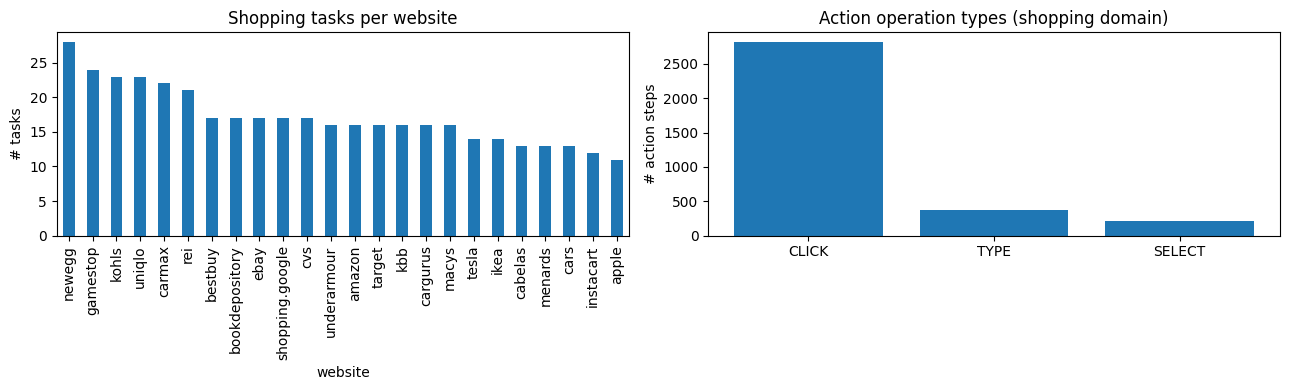

Operation counts: {'CLICK': 2817, 'TYPE': 369, 'SELECT': 216}


In [8]:
import matplotlib.pyplot as plt
from collections import Counter

# Operation-type distribution (CLICK / TYPE / SELECT) across all shopping action steps.
op_counter = Counter()
for t in shopping_train_tasks + shopping_test_tasks:
    for a in t["actions"]:
        op_counter[a["operation"]["op"]] += 1

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

shopping_df.groupby("website").size().sort_values(ascending=False).plot.bar(ax=axes[0])
axes[0].set_title("Shopping tasks per website")
axes[0].set_ylabel("# tasks")

axes[1].bar(op_counter.keys(), op_counter.values())
axes[1].set_title("Action operation types (shopping domain)")
axes[1].set_ylabel("# action steps")

plt.tight_layout()
plt.savefig(PROCESSED_DIR / "week4_eda_charts.png", dpi=150)
plt.show()

print("Operation counts:", dict(op_counter))


In [ ]:
# Persist the shopping-filtered subset (task-level metadata + full action records)

shopping_df.to_csv(PROCESSED_DIR / "shopping_tasks_index.csv", index=False)

with open(PROCESSED_DIR / "shopping_train.json", "w", encoding="utf-8") as f:
    json.dump(shopping_train_tasks, f)
with open(PROCESSED_DIR / "shopping_test.json", "w", encoding="utf-8") as f:
    json.dump(shopping_test_tasks, f)

print(f"Saved shopping-domain subset to {PROCESSED_DIR.resolve()}")


Saved shopping-domain subset to /content/mind2web_data/processed


Saved the shopping-filtered train/test subsets to disk so later weeks (and `Capstone B.ipynb`) can load them directly instead of re-filtering the full Mind2Web dump each time.

## Week 5 — Baseline 1: schema.org rule-based

Rule: if exactly one candidate carries schema.org product markup, predict it; otherwise abstain. Reports both coverage (how often it can answer) and accuracy when it does.

In [10]:
SCHEMA_ORG_KEYS = {"itemprop", "itemscope", "itemtype", "vocab", "typeof", "property"}


def candidate_attrs(candidate):
    raw = candidate.get("attributes", "{}")
    if isinstance(raw, str):
        try:
            return json.loads(raw)
        except json.JSONDecodeError:
            return {}
    return raw or {}


def has_schema_markup(candidate):
    attrs = candidate_attrs(candidate)
    return any(k.lower() in SCHEMA_ORG_KEYS for k in attrs) or "schema.org" in json.dumps(attrs).lower()


def schema_rule_predict(action):
    candidates = action["pos_candidates"] + action["neg_candidates"]
    hits = [c for c in candidates if has_schema_markup(c)]
    if len(hits) == 1:
        return hits[0]["backend_node_id"]
    return None  # abstain: zero or ambiguous (>1) markup hits


n_steps = 0
n_covered = 0
n_correct_when_covered = 0

for t in shopping_test_tasks:
    pos_ids_by_step = [{c["backend_node_id"] for c in a["pos_candidates"]} for a in t["actions"]]
    for a, pos_ids in zip(t["actions"], pos_ids_by_step):
        n_steps += 1
        pred = schema_rule_predict(a)
        if pred is not None:
            n_covered += 1
            if pred in pos_ids:
                n_correct_when_covered += 1

coverage = n_covered / n_steps if n_steps else 0.0
acc_when_covered = n_correct_when_covered / n_covered if n_covered else float("nan")
overall_step_accuracy = n_correct_when_covered / n_steps if n_steps else 0.0

print(f"Shopping test steps evaluated: {n_steps}")
print(f"Coverage (rule fires): {coverage:.1%}  ({n_covered}/{n_steps})")
print(f"Accuracy when it fires: {acc_when_covered:.1%}" if n_covered else "Accuracy when it fires: n/a (never fired)")
print(f"Overall step accuracy (abstain = wrong): {overall_step_accuracy:.1%}")

schema_baseline_results = {
    "n_steps": n_steps,
    "coverage": coverage,
    "accuracy_when_covered": acc_when_covered,
    "overall_step_accuracy": overall_step_accuracy,
}


Shopping test steps evaluated: 1093
Coverage (rule fires): 0.0%  (0/1093)
Accuracy when it fires: n/a (never fired)
Overall step accuracy (abstain = wrong): 0.0%


## Week 5 — Baseline 2: zero-shot closed model

Prompt `gpt-4o-mini` (or Gemini) with the task goal, action history, and a shortlist of candidates (the ground-truth element plus random negatives, since the ranker doesn't exist yet). The model answers with a letter, an operation, and a value.

In [ ]:
MODEL_PROVIDER = "openai"  # "openai" or "gemini"
KEY_NAME = "OPENAI_API_KEY" if MODEL_PROVIDER == "openai" else "GEMINI_API_KEY"

API_KEY = os.environ.get(KEY_NAME) or get_secret(KEY_NAME)
os.environ[KEY_NAME] = API_KEY  # so the SDK's default client can pick it up
print(f"{KEY_NAME} loaded ({'*' * 6}{API_KEY[-4:] if API_KEY else ''})")


OPENAI_API_KEY loaded (******XxIA)


In [ ]:
import random
import string

RNG_SEED = 42
N_TASKS_TO_SAMPLE = 131   
MAX_NEGATIVES_PER_STEP = 9  # + 1 positive = up to 10 multiple-choice options


def render_candidate(candidate):
    attrs = candidate_attrs(candidate)
    keep_keys = ["class", "id", "name", "type", "placeholder", "aria-label", "role", "value", "text", "title"]
    shown = {k: v for k, v in attrs.items() if k in keep_keys and v}
    attr_str = " ".join(f'{k}="{str(v)[:40]}"' for k, v in shown.items())
    return f"<{candidate.get('tag', '?')} {attr_str}>"[:200]


def build_choices(action, rng):
    pos = action["pos_candidates"][0]
    negs = action["neg_candidates"]
    sampled_negs = rng.sample(negs, k=min(MAX_NEGATIVES_PER_STEP, len(negs))) if negs else []
    pool = [("POS", pos)] + [("NEG", n) for n in sampled_negs]
    rng.shuffle(pool)
    letters = string.ascii_uppercase[: len(pool)]
    return [
        {"letter": letter, "kind": kind, "candidate": c, "backend_node_id": c["backend_node_id"]}
        for letter, (kind, c) in zip(letters, pool)
    ]


def build_prompt(task_goal, history_reprs, choices):
    history_block = "\n".join(f"  {i+1}. {h}" for i, h in enumerate(history_reprs)) or "  (first step)"
    choices_block = "\n".join(f"  {c['letter']}. {render_candidate(c['candidate'])}" for c in choices)
    return f"""You are a web agent completing a shopping checkout task.

TASK GOAL: {task_goal}

ACTIONS TAKEN SO FAR:
{history_block}

For the CURRENT step, choose which element to interact with from the candidates below, and what
operation to perform. Operations are one of CLICK, TYPE, SELECT. If TYPE, also give the exact text
value to type.

CANDIDATE ELEMENTS:
{choices_block}

Respond with EXACTLY one line in this format, nothing else:
LETTER | OPERATION | VALUE

VALUE should be empty for CLICK/SELECT. Example: "C | TYPE | bath towels" or "A | CLICK | "."""


def parse_model_response(text):
    line = text.strip().splitlines()[0]
    parts = [p.strip() for p in line.split("|")]
    letter = parts[0][:1].upper() if parts else ""
    op = parts[1].upper() if len(parts) > 1 else ""
    value = parts[2] if len(parts) > 2 else ""
    return letter, op, value


print("Zero-shot baseline helpers defined.")


Zero-shot baseline helpers defined.


In [13]:
def call_model(prompt):
    if MODEL_PROVIDER == "openai":
        from openai import OpenAI
        client = OpenAI()
        resp = client.chat.completions.create(
            model="gpt-4o-mini",
            messages=[{"role": "user", "content": prompt}],
            temperature=0,
        )
        return resp.choices[0].message.content
    else:
        import google.generativeai as genai
        genai.configure(api_key=API_KEY)
        model = genai.GenerativeModel("gemini-1.5-flash")
        return model.generate_content(prompt).text


rng = random.Random(RNG_SEED)
sampled_tasks = rng.sample(shopping_test_tasks, k=min(N_TASKS_TO_SAMPLE, len(shopping_test_tasks)))
print(f"Sampled {len(sampled_tasks)} shopping test tasks for the zero-shot baseline "
      f"({sum(len(t['actions']) for t in sampled_tasks)} action steps total).")


Sampled 131 shopping test tasks for the zero-shot baseline (1093 action steps total).


In [14]:
def normalize_value(v):
    return " ".join(v.strip().lower().split())


zero_shot_step_results = []
skipped_no_pos_candidate = 0

for t_idx, t in enumerate(sampled_tasks):
    task_goal = t["confirmed_task"]
    history_reprs = []
    task_all_steps_correct = True

    for step_idx, action in enumerate(t["actions"]):
        if not action["pos_candidates"]:
            # Per Mind2Web's dataset card: pos_candidates can be empty when
            # the ground-truth element didn't survive HTML pruning (it still
            # exists in raw_html, just not in cleaned_html). There's no
            # correct choice to offer the model in that case, so this step
            # isn't a fair test of action-selection — skip it from scoring
            # rather than counting it as a guaranteed wrong answer.
            skipped_no_pos_candidate += 1
            history_reprs.append(t["action_reprs"][step_idx])
            continue

        choices = build_choices(action, rng)
        prompt = build_prompt(task_goal, history_reprs, choices)

        gt_op = action["operation"]["op"]
        gt_value = action["operation"].get("value", "")
        gt_ids = {c["backend_node_id"] for c in action["pos_candidates"]}

        try:
            raw_response = call_model(prompt)
            letter, pred_op, pred_value = parse_model_response(raw_response)
        except Exception as e:
            letter, pred_op, pred_value = "", "", ""
            raw_response = f"[ERROR: {e}]"

        chosen = next((c for c in choices if c["letter"] == letter), None)
        element_correct = bool(chosen) and chosen["backend_node_id"] in gt_ids
        operation_correct = pred_op == gt_op
        value_correct = True if gt_op != "TYPE" else normalize_value(pred_value) == normalize_value(gt_value)
        step_success = element_correct and operation_correct and value_correct
        task_all_steps_correct &= step_success

        zero_shot_step_results.append({
            "task_idx": t_idx, "step_idx": step_idx, "website": t["website"],
            "gt_op": gt_op, "pred_op": pred_op,
            "element_correct": element_correct, "operation_correct": operation_correct,
            "value_correct": value_correct, "step_success": step_success,
            "raw_response": raw_response,
        })

        history_reprs.append(t["action_reprs"][step_idx])

    print(f"[{t_idx+1}/{len(sampled_tasks)}] {t['website']} — task_success={task_all_steps_correct} "
          f"({len(t['actions'])} steps)")

zero_shot_df = pd.DataFrame(zero_shot_step_results)
zero_shot_df.to_csv(PROCESSED_DIR / "zero_shot_baseline_step_results.csv", index=False)
print(f"\nEvaluated {len(zero_shot_df)} action steps across {len(sampled_tasks)} tasks.")


[1/131] rei — task_success=False (6 steps)
[2/131] kohls — task_success=False (6 steps)
[3/131] cars — task_success=False (9 steps)
[4/131] cabelas — task_success=False (4 steps)
[5/131] cars — task_success=False (6 steps)
[6/131] gamestop — task_success=False (8 steps)
[7/131] bestbuy — task_success=False (4 steps)
[8/131] underarmour — task_success=False (10 steps)
[9/131] bestbuy — task_success=False (8 steps)
[10/131] bestbuy — task_success=False (10 steps)
[11/131] bestbuy — task_success=False (4 steps)
[12/131] cars — task_success=False (11 steps)
[13/131] tesla — task_success=False (3 steps)
[14/131] shopping.google — task_success=False (8 steps)
[15/131] target — task_success=False (18 steps)
[16/131] newegg — task_success=False (4 steps)
[17/131] newegg — task_success=False (46 steps)
[18/131] cars — task_success=False (12 steps)
[19/131] carmax — task_success=False (10 steps)
[20/131] gamestop — task_success=False (5 steps)
[21/131] uniqlo — task_success=False (2 steps)
[22/1

The loop above queried `gpt-4o-mini` for every scorable step across the sampled tasks, recording per-step correctness (element, operation, value) and saving the raw results to CSV. The next cell aggregates those per-step results into the final baseline metrics.

In [15]:
try:
    from sklearn.metrics import f1_score
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "scikit-learn"])
    from sklearn.metrics import f1_score

task_success = (
    zero_shot_df.groupby("task_idx")["step_success"].all()
    if len(zero_shot_df) else pd.Series(dtype=bool)
)

zero_shot_results = {
    "n_steps": len(zero_shot_df),
    "n_tasks": zero_shot_df["task_idx"].nunique() if len(zero_shot_df) else 0,
    "element_accuracy": zero_shot_df["element_correct"].mean() if len(zero_shot_df) else float("nan"),
    # macro F1 over the operation classes actually observed (CLICK/TYPE/SELECT),
    # comparing predicted vs. ground-truth operation per step.
    "operation_f1_macro": (
        f1_score(zero_shot_df["gt_op"], zero_shot_df["pred_op"], average="macro", zero_division=0)
        if len(zero_shot_df) else float("nan")
    ),
    "step_success_rate": zero_shot_df["step_success"].mean() if len(zero_shot_df) else float("nan"),
    "task_success_rate": task_success.mean() if len(task_success) else float("nan"),
}

summary = pd.DataFrame([
    {"baseline": "schema.org rule-based", "metric": "step accuracy (abstain=wrong)",
     "value": schema_baseline_results["overall_step_accuracy"]},
    {"baseline": "schema.org rule-based", "metric": "coverage",
     "value": schema_baseline_results["coverage"]},
    {"baseline": "zero-shot gpt-4o-mini", "metric": "element accuracy",
     "value": zero_shot_results["element_accuracy"]},
    {"baseline": "zero-shot gpt-4o-mini", "metric": "operation F1 (macro)",
     "value": zero_shot_results["operation_f1_macro"]},
    {"baseline": "zero-shot gpt-4o-mini", "metric": "step success rate",
     "value": zero_shot_results["step_success_rate"]},
    {"baseline": "zero-shot gpt-4o-mini", "metric": "task success rate",
     "value": zero_shot_results["task_success_rate"]},
])
summary["value"] = summary["value"].map(lambda v: f"{v:.1%}" if pd.notnull(v) else "n/a")

print("=== Week 5 baseline numbers (shopping-domain cross-website test, "
      f"n={zero_shot_results['n_tasks']} tasks / {zero_shot_results['n_steps']} steps sampled) ===")
display(summary)

summary.to_csv(PROCESSED_DIR / "week5_baseline_summary.csv", index=False)


=== Week 5 baseline numbers (shopping-domain cross-website test, n=131 tasks / 1036 steps sampled) ===


,baseline,metric,value
0,schema.org rule-based,step accuracy (abstain=wrong),0.0%
1,schema.org rule-based,coverage,0.0%
2,zero-shot gpt-4o-mini,element accuracy,49.6%
3,zero-shot gpt-4o-mini,operation F1 (macro),82.2%
4,zero-shot gpt-4o-mini,step success rate,42.3%
5,zero-shot gpt-4o-mini,task success rate,3.8%


## Week 6 — Train the shopping-specialised element ranker

Train a cross-encoder (`roberta-base`, via `sentence-transformers`) that scores how likely each DOM candidate is to be the correct target for a step — following Deng et al.'s (2023) Mind2Web recipe: DOM-tree candidate representation, one positive plus 5 sampled negatives per step, 5 epochs. A small overfitting test checks the training loop before the full run. Evaluated with MRR@10, top-1 accuracy, and Recall@k — Recall@10 is the ceiling on Week 7's element accuracy.

*Note: uses `roberta-base` in place of the proposal's `deberta-v3-base`, which trained unstably in this environment.*

In [16]:
for pip_name, import_name in [
    ("sentence-transformers", "sentence_transformers"),
    ("lxml", "lxml"),
    ("sentencepiece", "sentencepiece"),  # required by the deberta-v3 tokenizer
]:
    _ensure(pip_name, import_name)

import torch

HAS_GPU = torch.cuda.is_available()
if HAS_GPU:
    print(f"GPU available: {torch.cuda.get_device_name(0)}")
else:
    print(
        "WARNING: no GPU detected. Training microsoft/deberta-v3-base on CPU will be very slow.\n"
        "On Colab: Runtime -> Change runtime type -> select a GPU (e.g. T4), then re-run this cell."
    )


GPU available: Tesla T4


In [17]:
# Ported from Deng et al. (2023), OSU-NLP-Group/Mind2Web,
# src/data_utils/dom_utils.py (candidate_generation ranker recipe).
# https://github.com/OSU-NLP-Group/Mind2Web
#
# Only the tree-pruning / text-rendering utilities are needed here — the
# repo's build_dom_tree() reconstructs cleaned_html from a raw CDP snapshot,
# which Mind2Web's HuggingFace release already gives us pre-computed as the
# `cleaned_html` string per action step.
import copy
import re
from lxml import etree

_SALIENT_ATTRS = {
    "alt", "aria_description", "aria_label", "aria_role", "input_checked",
    "input_value", "label", "name", "option_selected", "placeholder",
    "role", "text_value", "title", "type", "value",
}


def _get_descendants(node, max_depth, current_depth=0):
    if current_depth > max_depth:
        return []
    descendants = []
    for child in node:
        descendants.append(child)
        descendants.extend(_get_descendants(child, max_depth, current_depth + 1))
    return descendants


def prune_tree(dom_tree, candidate_set, max_depth=5, max_children=50, max_sibling=3):
    nodes_to_keep = set()
    for candidate_id in candidate_set:
        matches = dom_tree.xpath(f'//*[@backend_node_id="{candidate_id}"]')
        if not matches:
            continue
        candidate_node = matches[0]
        nodes_to_keep.add(candidate_node.attrib["backend_node_id"])
        nodes_to_keep.update(
            [x.attrib.get("backend_node_id", "") for x in candidate_node.xpath("ancestor::*")]
        )
        nodes_to_keep.update(
            [x.attrib.get("backend_node_id", "") for x in _get_descendants(candidate_node, max_depth)][:max_children]
        )
        parent = candidate_node.getparent()
        if parent is not None:
            siblings = [x for x in parent.getchildren() if x.tag != "text"]
            idx_in_sibling = siblings.index(candidate_node)
            nodes_to_keep.update(
                [x.attrib.get("backend_node_id", "") for x in siblings[
                    max(0, idx_in_sibling - max_sibling): idx_in_sibling + max_sibling + 1
                ]]
            )
    new_tree = copy.deepcopy(dom_tree)
    for node in new_tree.xpath("//*")[::-1]:
        if node.tag != "text":
            is_keep = node.attrib.get("backend_node_id", "") in nodes_to_keep
            is_candidate = node.attrib.get("backend_node_id", "") in candidate_set
        else:
            is_keep = node.getparent().attrib.get("backend_node_id", "") in nodes_to_keep
            is_candidate = node.getparent().attrib.get("backend_node_id", "") in candidate_set
        if not is_keep and node.getparent() is not None:
            node.getparent().remove(node)
        else:
            if not is_candidate or node.tag == "text":
                node.attrib.pop("backend_node_id", None)
            if (
                len(node.attrib) == 0
                and not any(x.tag == "text" for x in node.getchildren())
                and node.getparent() is not None
                and node.tag != "text"
                and len(node.getchildren()) <= 1
            ):
                for child in node.getchildren():
                    node.addprevious(child)
                node.getparent().remove(node)
    return new_tree


def _get_attribute_repr(node, max_value_length=5, max_length=20):
    attr_values_set = set()
    attr_values = ""
    for attr in [
        "role", "aria_role", "type", "alt", "aria_description", "aria_label",
        "label", "title", "name", "text_value", "value", "placeholder",
        "input_checked", "input_value", "option_selected", "class",
    ]:
        if attr in node.attrib and node.attrib[attr] is not None:
            value = node.attrib[attr].lower()
            if value in ["hidden", "none", "presentation", "null", "undefined"] or value.startswith("http"):
                continue
            value = value.split()
            value = " ".join([v for v in value if len(v) < 15][:max_value_length])
            if value and value not in attr_values_set:
                attr_values_set.add(value)
                attr_values += value + " "
    uid = node.attrib.get("backend_node_id", "")
    node.attrib.clear()
    if uid:
        node.attrib["id"] = uid
    if attr_values:
        node.attrib["meta"] = " ".join(attr_values.split()[:max_length])


def get_tree_repr(tree, max_value_length=5, max_length=20, id_mapping=None, keep_html_brackets=False):
    if id_mapping is None:
        id_mapping = {}
    tree = etree.fromstring(tree) if isinstance(tree, str) else copy.deepcopy(tree)
    for node in tree.xpath("//*"):
        if node.tag != "text":
            if "backend_node_id" in node.attrib:
                if node.attrib["backend_node_id"] not in id_mapping:
                    id_mapping[node.attrib["backend_node_id"]] = len(id_mapping)
                node.attrib["backend_node_id"] = str(id_mapping[node.attrib["backend_node_id"]])
            _get_attribute_repr(node, max_value_length, max_length)
        else:
            node.text = " ".join((node.text or "").split()[:max_length])
    tree_repr = etree.tostring(tree, encoding="unicode")

    tree_repr = tree_repr.replace('"', " ")
    tree_repr = tree_repr.replace("meta= ", "").replace("id= ", "id=").replace(" >", ">")
    tree_repr = re.sub(r"<text>(.*?)</text>", r"\1", tree_repr)
    if not keep_html_brackets:
        tree_repr = tree_repr.replace("/>", "$/$>")
        tree_repr = re.sub(r"</(.+?)>", r")", tree_repr)
        tree_repr = re.sub(r"<(.+?)>", r"(\1", tree_repr)
        tree_repr = tree_repr.replace("$/$", ")")

    for k, v in [
        ("&quot;", '"'), ("&amp;", "&"), ("&lt;", "<"), ("&gt;", ">"),
        ("&nbsp;", " "), ("&ndash;", "-"), ("&rsquo;", "'"), ("&lsquo;", "'"),
        ("&ldquo;", '"'), ("&rdquo;", '"'), ("&#39;", "'"), ("&#40;", "("), ("&#41;", ")"),
    ]:
        tree_repr = tree_repr.replace(k, v)
    tree_repr = re.sub(r"\s+", " ", tree_repr).strip()

    return tree_repr, id_mapping


def format_candidate(dom_tree, candidate, keep_html_brackets=False):
    node_tree = prune_tree(dom_tree, [candidate["backend_node_id"]])
    matches = node_tree.xpath("//*[@backend_node_id]")
    if not matches:
        return "ancestors: \ntarget: "
    c_node = matches[0]
    if c_node.getparent() is not None:
        c_node.getparent().remove(c_node)
        ancestor_repr, _ = get_tree_repr(node_tree, id_mapping={}, keep_html_brackets=keep_html_brackets)
    else:
        ancestor_repr = ""
    subtree_repr, _ = get_tree_repr(c_node, id_mapping={}, keep_html_brackets=keep_html_brackets)
    subtree_repr = " ".join(subtree_repr.split()[:100]) if subtree_repr.strip() else ""
    if ancestor_repr.strip():
        ancestor_repr = re.sub(r"\s*\(\s*", "/", ancestor_repr)
        ancestor_repr = re.sub(r"\s*\)\s*", "", ancestor_repr)
        ancestor_repr = " ".join(ancestor_repr.split()[-50:])
    else:
        ancestor_repr = ""
    return f"ancestors: {ancestor_repr}\n" + f"target: {subtree_repr}"


print("dom_utils ported: prune_tree, get_tree_repr, format_candidate.")


dom_utils ported: prune_tree, get_tree_repr, format_candidate.


These three functions turn a raw DOM into the ranker's input text: `prune_tree` keeps a candidate plus its ancestors, a bounded set of descendants, and nearby siblings (dropping everything else, and collapsing attribute-less single-child wrapper nodes); `get_tree_repr` compresses that pruned tree into a compact bracket-notation string, keeping only a short list of salient attributes; `format_candidate` splits the result into an `ancestors:` string and a `target:` string for one specific candidate.

In [18]:
import random
from tqdm.auto import tqdm

RANKER_SEED = 123  # matches the official config.yaml `seed`
MAX_NEG_PER_STEP_FORMAT = 20  # see markdown above: compute-driven cap, not a change to neg_ratio

ranker_rng = random.Random(RANKER_SEED)


def build_ranker_examples(tasks, max_neg_per_step, require_positive):
    """Flatten tasks into per-step examples with formatted (query, candidate_text)
    pairs, mirroring the official get_data_split()/format_candidates() pipeline.
    """
    examples = []
    n_skipped_no_pos = 0
    n_skipped_parse_error = 0
    for t in tqdm(tasks, desc="formatting tasks"):
        for step_idx, action in enumerate(t["actions"]):
            if require_positive and not action["pos_candidates"]:
                n_skipped_no_pos += 1
                continue
            try:
                dom_tree = etree.fromstring(action["cleaned_html"].encode("utf-8"))
            except Exception:
                n_skipped_parse_error += 1
                continue

            query = (
                f'task is: {t["confirmed_task"]}\n'
                f'Previous actions: {"; ".join(t["action_reprs"][:step_idx][-3:])}'
            )

            positives = [
                (c["backend_node_id"], format_candidate(dom_tree, c))
                for c in action["pos_candidates"]
            ]
            neg_pool = action["neg_candidates"]
            if len(neg_pool) > max_neg_per_step:
                neg_pool = ranker_rng.sample(neg_pool, k=max_neg_per_step)
            negatives = [
                (c["backend_node_id"], format_candidate(dom_tree, c))
                for c in neg_pool
            ]

            examples.append({
                "annotation_id": t["annotation_id"],
                "action_uid": action["action_uid"],
                "website": t["website"],
                "confirmed_task": t["confirmed_task"],
                "query": query,
                "pos_candidates": positives,
                "neg_candidates": negatives,
            })
    print(f"Built {len(examples)} examples "
          f"({n_skipped_no_pos} skipped: no pos_candidates, "
          f"{n_skipped_parse_error} skipped: cleaned_html parse error).")
    return examples


ranker_train_examples = build_ranker_examples(
    shopping_train_tasks, max_neg_per_step=MAX_NEG_PER_STEP_FORMAT, require_positive=True
)


formatting tasks:   0%|          | 0/281 [00:00<?, ?it/s]

Built 2216 examples (93 skipped: no pos_candidates, 0 skipped: cleaned_html parse error).


`build_ranker_examples` turns every step into one training example: a `query` string (task + last 3 prior actions) paired with every ground-truth candidate's pruned DOM text, plus up to `MAX_NEG_PER_STEP_FORMAT` randomly sampled negative candidates (capped for compute, separate from the `neg_ratio` used later during actual batch sampling).

In [ ]:
MAX_NEG_PER_STEP_EVAL = 50  

# the official evaluate.py uses max_neg=-1 (all); capped here for the same compute reason
# is_train=False in the official recipe does NOT filter out steps with empty
# pos_candidates — such a step just contributes 0 to every metric (there is
# nothing to find), which is the correct behaviour for a ranker-recall
# evaluation and differs deliberately from how the Week 5 zero-shot baseline
# handled the same edge case (there, no valid MCQ could be posed at all, so
# those steps were excluded rather than scored).
ranker_test_examples = build_ranker_examples(
    shopping_test_tasks, max_neg_per_step=MAX_NEG_PER_STEP_EVAL, require_positive=False
)


formatting tasks:   0%|          | 0/131 [00:00<?, ?it/s]

Built 1093 examples (0 skipped: no pos_candidates, 0 skipped: cleaned_html parse error).


In [ ]:
# Ported from Deng et al. (2023) src/candidate_generation/dataloader.py — the
# per-epoch positive/negative sampling scheme (neg_ratio) that defines what
# "1 epoch" means for this dataset.
#
# FIX (not in the original): the official dataloader.py pairs texts as
# [candidate, query], but the official metric.py evaluates as [query, candidate]
# -- an inconsistency in the published code itself. Training here uses
# [query, candidate] to match the evaluator, so the model is actually being
# tested on the input format it was trained on.

from sentence_transformers import InputExample
from torch.utils.data import Dataset


class CandidateRankDataset(Dataset):
    def __init__(self, data, neg_ratio=5, rng=None):
        self.data = data
        self.neg_ratio = neg_ratio
        self.rng = rng or random.Random()

    def __len__(self):
        return len(self.data) * (1 + self.neg_ratio)

    def __getitem__(self, idx):
        sample = self.data[idx // (1 + self.neg_ratio)]
        if idx % (1 + self.neg_ratio) == 0 or len(sample["neg_candidates"]) == 0:
            candidate = self.rng.choice(sample["pos_candidates"])
            label = 1
        else:
            candidate = self.rng.choice(sample["neg_candidates"])
            label = 0
        return InputExample(texts=[sample["query"], candidate[1]], label=label)


print(f"Training examples (pre-expansion): {len(ranker_train_examples)}")
print(f"Effective dataset size at neg_ratio=5: {len(ranker_train_examples) * 6}")


Training examples (pre-expansion): 2216
Effective dataset size at neg_ratio=5: 13296


In [ ]:
import torch.nn.functional as F
from sentence_transformers import CrossEncoder
from torch.utils.data import DataLoader


def train_cross_encoder(model, examples, neg_ratio, batch_size, lr, epochs, warmup_fraction,
                         seed, max_length, log_every=50, desc="training", max_consecutive_nonfinite=5):
    """Manual training loop, replacing CrossEncoder.fit(). Same loss (BCEWithLogitsLoss),
    optimizer (AdamW), and linear-warmup-then-decay schedule as the published recipe."""
    dataset = CandidateRankDataset(examples, neg_ratio=neg_ratio, rng=random.Random(seed))
    dataloader = DataLoader(dataset, shuffle=True, batch_size=batch_size, collate_fn=lambda batch: batch)
    steps_per_epoch = len(dataloader)
    total_steps = steps_per_epoch * epochs
    warmup_steps = int(steps_per_epoch * warmup_fraction)

    def lr_lambda(step):
        if step < warmup_steps:
            return (step + 1) / max(1, warmup_steps)  # never exactly 0 -- see docstring
        return max(0.0, (total_steps - step) / max(1, total_steps - warmup_steps))

    optimizer = torch.optim.AdamW(model.model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

    model.model.train()
    losses = []
    step = 0
    consecutive_nonfinite = 0
    for epoch in range(epochs):
        for batch in tqdm(dataloader, desc=f"{desc} epoch {epoch + 1}/{epochs}"):
            texts_a = [ex.texts[0] for ex in batch]
            texts_b = [ex.texts[1] for ex in batch]
            labels = torch.tensor([ex.label for ex in batch], dtype=torch.float, device=model.model.device)

            tokens = model.tokenizer(
                texts_a, texts_b, padding=True, truncation="longest_first",
                max_length=max_length, return_tensors="pt",
            ).to(model.model.device)

            logits = model.model(**tokens)[0].view(-1)

            bad = ~torch.isfinite(logits)
            if bad.any():
                print(f"\n  step {step + 1}: {bad.sum().item()}/{len(logits)} non-finite logit(s). "
                      f"Dumping offending input(s):")
                for i in torch.nonzero(bad).flatten().tolist():
                    n_tokens = int(tokens["attention_mask"][i].sum().item())
                    print(f"    --- item {i} --- label={labels[i].item()}  logit={logits[i].item()}  "
                          f"real_token_count={n_tokens}  padded_seq_len={tokens['input_ids'].shape[1]}")
                    print(f"    text_a (query) [:200 chars]: {texts_a[i][:200]!r}")
                    print(f"    text_b (candidate) [:500 chars]: {texts_b[i][:500]!r}")
                consecutive_nonfinite += 1
                optimizer.zero_grad()
                if consecutive_nonfinite >= max_consecutive_nonfinite:
                    raise RuntimeError(
                        f"{max_consecutive_nonfinite} consecutive non-finite batches -- see the dumped "
                        "inputs above for the likely culprit(s). Stop here."
                    )
                continue

            loss = F.binary_cross_entropy_with_logits(logits, labels)
            if not torch.isfinite(loss):
                print(f"  step {step + 1}: all logits finite but loss is non-finite ({loss.item()}) -- unexpected")
                consecutive_nonfinite += 1
                optimizer.zero_grad()
                if consecutive_nonfinite >= max_consecutive_nonfinite:
                    raise RuntimeError(f"{max_consecutive_nonfinite} consecutive non-finite losses -- stop here.")
                continue

            optimizer.zero_grad()
            loss.backward()
            grad_norm = torch.nn.utils.clip_grad_norm_(model.model.parameters(), max_norm=1.0)
            if not torch.isfinite(grad_norm):
                consecutive_nonfinite += 1
                print(f"  step {step + 1}: non-finite grad norm -- skipping optimizer step "
                      f"({consecutive_nonfinite}/{max_consecutive_nonfinite} consecutive)")
                optimizer.zero_grad()
                if consecutive_nonfinite >= max_consecutive_nonfinite:
                    raise RuntimeError(f"{max_consecutive_nonfinite} consecutive non-finite gradients -- stop here.")
                continue

            lr_used = optimizer.param_groups[0]["lr"]
            optimizer.step()
            scheduler.step()

            if any(torch.isnan(p).any() for p in model.model.parameters()):
                raise RuntimeError(
                    f"Model parameters became NaN immediately after step {step + 1}'s optimizer.step() "
                    f"(lr used: {lr_used}). This is the exact failure mode already root-caused once "
                    "(an exact lr=0.0 step) -- if it recurs here, something else is now triggering the "
                    "same class of instability and needs fresh investigation, not the same fix again."
                )

            consecutive_nonfinite = 0
            loss_val = loss.item()
            losses.append(loss_val)
            step += 1
            if step % log_every == 0 or step == 1:
                recent = losses[-log_every:]
                print(f"  step {step}/{total_steps}  loss={loss_val:.4f}  "
                      f"(avg last {len(recent)}: {sum(recent) / len(recent):.4f})")

    model.model.eval()
    return losses


print("train_cross_encoder defined (warmup fix applied: lr is never exactly 0).")


train_cross_encoder defined (warmup fix applied: lr is never exactly 0).


In [23]:
from sentence_transformers import CrossEncoder
from torch.utils.data import DataLoader

# Hyperparameters below are the official config.yaml values, unchanged.
NEG_RATIO = 5
BATCH_SIZE = 32
LEARNING_RATE = 3e-5
EPOCHS = 5
WARMUP_FRACTION = 0.5
MAX_SEQ_LENGTH = 512

# Base encoder: roberta-base, NOT the recipe's microsoft/deberta-v3-base -- see the Week 6
# markdown for the full account. Every other element of the published recipe (architecture
# family, loss, neg_ratio, batch size, learning rate, epochs, warmup schedule, DOM-pruning
# candidate representation) is unchanged; only the specific pretrained checkpoint differs.
RANKER_BASE_MODEL = "roberta-base"
RANKER_MODEL_DIR = str(PROCESSED_DIR / "shopping_ranker")

torch.manual_seed(RANKER_SEED)
ranker_model = CrossEncoder(
    RANKER_BASE_MODEL,
    device="cuda" if HAS_GPU else "cpu",
    num_labels=1,
    max_length=MAX_SEQ_LENGTH,
)

ranker_losses = train_cross_encoder(
    ranker_model, ranker_train_examples, neg_ratio=NEG_RATIO, batch_size=BATCH_SIZE,
    lr=LEARNING_RATE, epochs=EPOCHS, warmup_fraction=WARMUP_FRACTION, seed=RANKER_SEED,
    max_length=MAX_SEQ_LENGTH, log_every=50, desc="ranker",
)

ranker_model.save(RANKER_MODEL_DIR)
print(f"\nFinal loss: first={ranker_losses[0]:.4f}  last={ranker_losses[-1]:.4f}")
print(f"Ranker saved to {RANKER_MODEL_DIR}")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


ranker epoch 1/5:   0%|          | 0/416 [00:00<?, ?it/s]

  step 1/2080  loss=0.6414  (avg last 1: 0.6414)
  step 50/2080  loss=0.3260  (avg last 50: 0.5631)
  step 100/2080  loss=0.2730  (avg last 50: 0.4701)
  step 150/2080  loss=0.3802  (avg last 50: 0.4062)
  step 200/2080  loss=0.2990  (avg last 50: 0.3369)
  step 250/2080  loss=0.3354  (avg last 50: 0.3214)
  step 300/2080  loss=0.1579  (avg last 50: 0.2575)
  step 350/2080  loss=0.3671  (avg last 50: 0.2673)
  step 400/2080  loss=0.5210  (avg last 50: 0.2381)


ranker epoch 2/5:   0%|          | 0/416 [00:00<?, ?it/s]

  step 450/2080  loss=0.1641  (avg last 50: 0.1903)
  step 500/2080  loss=0.3418  (avg last 50: 0.2354)
  step 550/2080  loss=0.2145  (avg last 50: 0.1939)
  step 600/2080  loss=0.0916  (avg last 50: 0.2234)
  step 650/2080  loss=0.1119  (avg last 50: 0.2010)
  step 700/2080  loss=0.1301  (avg last 50: 0.2234)
  step 750/2080  loss=0.0482  (avg last 50: 0.2040)
  step 800/2080  loss=0.2395  (avg last 50: 0.1803)


... (4 outputs left out)

ranker epoch 5/5:   0%|          | 0/416 [00:00<?, ?it/s]

  step 1700/2080  loss=0.0183  (avg last 50: 0.0934)
  step 1750/2080  loss=0.0224  (avg last 50: 0.0999)
  step 1800/2080  loss=0.0353  (avg last 50: 0.0931)
  step 1850/2080  loss=0.1109  (avg last 50: 0.1200)
  step 1900/2080  loss=0.0522  (avg last 50: 0.0885)
  step 1950/2080  loss=0.0887  (avg last 50: 0.0979)
  step 2000/2080  loss=0.0507  (avg last 50: 0.1158)
  step 2050/2080  loss=0.1341  (avg last 50: 0.1092)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Final loss: first=0.6414  last=0.0309
Ranker saved to /content/mind2web_data/processed/shopping_ranker


This cell instantiates the `roberta-base` cross-encoder and runs the full 5-epoch training loop, saving the trained ranker to disk. The next cells evaluate it on the held-out shopping test split.

In [24]:
# Adapted from Deng et al. (2023) src/candidate_generation/metric.py
# (CERerankingEvaluator) — same metrics, same ranking logic; simplified to a
# plain function since we don't need the sentence-transformers Evaluator
# callback interface (the official fit() call doesn't use it either).
import numpy as np

RECALL_KS = [3, 5, 10, 20, 50, 100]


def evaluate_ranker(model, examples, mrr_at_k=10, batch_size=300):
    all_mrr, all_acc = [], []
    all_recall = {k: [] for k in RECALL_KS}
    per_step_ranks = {}

    for inst in tqdm(examples, desc="evaluating"):
        positive, negative = inst["pos_candidates"], inst["neg_candidates"]
        doc_ids = [d[0] for d in positive + negative]
        is_relevant = [True] * len(positive) + [False] * len(negative)

        doc_dict, doc_mapping, unique_docs = {}, [], []
        for _, text in positive + negative:
            if text not in doc_dict:
                doc_dict[text] = len(doc_dict)
                unique_docs.append(text)
            doc_mapping.append(doc_dict[text])

        if not unique_docs:
            continue

        model_input = [[inst["query"], doc] for doc in unique_docs]
        pred_scores = model.predict(model_input, convert_to_numpy=True, show_progress_bar=False, batch_size=batch_size)
        pred_scores = np.array([pred_scores[i] for i in doc_mapping])
        order = np.argsort(-pred_scores)

        per_step_ranks[f'{inst["annotation_id"]}_{inst["action_uid"]}'] = {
            doc_ids[idx]: rank for rank, idx in enumerate(order)
        }

        mrr, acc = 0.0, 0.0
        recall_hits = {k: 0.0 for k in RECALL_KS}
        for rank, idx in enumerate(order[: max(100, mrr_at_k)]):
            if is_relevant[idx]:
                if rank == 0:
                    acc = 1.0
                for k in RECALL_KS:
                    if rank < k:
                        recall_hits[k] = 1.0
                if rank < mrr_at_k:
                    mrr = 1 / (rank + 1)
                break
        all_mrr.append(mrr)
        all_acc.append(acc)
        for k in RECALL_KS:
            all_recall[k].append(recall_hits[k])

    results = {
        "n_steps_evaluated": len(all_mrr),
        f"mrr@{mrr_at_k}": float(np.mean(all_mrr)) if all_mrr else float("nan"),
        "acc_top1": float(np.mean(all_acc)) if all_acc else float("nan"),
        **{f"recall@{k}": float(np.mean(all_recall[k])) if all_recall[k] else float("nan") for k in RECALL_KS},
    }
    return results, per_step_ranks


In [25]:
ranker_results, ranker_per_step_ranks = evaluate_ranker(ranker_model, ranker_test_examples, mrr_at_k=10, batch_size=300)

print(f"=== Shopping-specialised RoBERTa ranker — held-out shopping test split "
      f"(n={ranker_results['n_steps_evaluated']} steps, capped at {MAX_NEG_PER_STEP_EVAL} negatives/step) ===\n")
for k, v in ranker_results.items():
    if k == "n_steps_evaluated":
        continue
    print(f"  {k:>12s}: {v:.1%}")

with open(PROCESSED_DIR / "week6_ranker_eval.json", "w") as f:
    json.dump(ranker_results, f, indent=2)
print(f"\nSaved to {PROCESSED_DIR / 'week6_ranker_eval.json'}")
print(
    "\nReminder: these Recall@k numbers are measured against a negative pool capped at "
    f"{MAX_NEG_PER_STEP_EVAL} per step (see the disclosed simplification in the Week 6 intro), "
    "so they are an optimistic estimate relative to Deng et al.'s full-candidate-pool setting."
)


evaluating:   0%|          | 0/1093 [00:00<?, ?it/s]

=== Shopping-specialised RoBERTa ranker — held-out shopping test split (n=1093 steps, capped at 50 negatives/step) ===

        mrr@10: 68.6%
      acc_top1: 56.9%
      recall@3: 78.3%
      recall@5: 84.4%
     recall@10: 89.2%
     recall@20: 93.0%
     recall@50: 94.8%
    recall@100: 94.8%

Saved to /content/mind2web_data/processed/week6_ranker_eval.json

Reminder: these Recall@k numbers are measured against a negative pool capped at 50 per step (see the disclosed simplification in the Week 6 intro), so they are an optimistic estimate relative to Deng et al.'s full-candidate-pool setting.


## Week 7 — Fallback pipeline: ranker + zero-shot selector

Replace Week 5's oracle shortlist with the real one: the Week 6 ranker's actual top-10 candidates for every test step, fed into the same zero-shot selector. This is the "fallback pipeline" milestone, run on the full 131-task shopping test split.

In [26]:
import numpy as np

RANKER_SHORTLIST_K = 10  # see markdown above: ties directly to Week 6's Recall@10
MAX_TASKS_FOR_FALLBACK = None  # set to an int to subsample tasks for a faster/cheaper run

# Ground truth (operation, value, true element ids) lives on the original task/action
# objects, not on ranker_test_examples (which only carries what the ranker needs) --
# look it up by (annotation_id, action_uid) instead of reformatting anything.
action_lookup = {}
for _t in shopping_test_tasks:
    for _a in _t["actions"]:
        action_lookup[(_t["annotation_id"], _a["action_uid"])] = (_t, _a)


def rank_candidates(model, example, k, batch_size=64):
    """Score every real candidate for this step with the trained ranker and
    return its top-k (backend_node_id, formatted_text) pairs, best first.
    Pair order matches training: [query, candidate] (see the Week 6 dataset fix).
    """
    pool = example["pos_candidates"] + example["neg_candidates"]
    if not pool:
        return []
    texts = [c[1] for c in pool]
    scores = model.predict(
        [[example["query"], t] for t in texts],
        convert_to_numpy=True, show_progress_bar=False, batch_size=batch_size,
    )
    order = np.argsort(-scores)[:k]
    return [pool[i] for i in order]


print(f"Ranker shortlist size K={RANKER_SHORTLIST_K}. "
      f"action_lookup covers {len(action_lookup)} action steps.")

Ranker shortlist size K=10. action_lookup covers 1093 action steps.


In [27]:
def build_prompt_from_shortlist(query, choices):
    choices_block = "\n\n".join(f"{c['letter']}.\n{c['text']}" for c in choices)
    return f"""You are a web agent completing a shopping checkout task.

{query}

For the CURRENT step, choose which element to interact with from the candidates below (each shown
as its DOM ancestry and its own subtree), and what operation to perform. Operations are one of
CLICK, TYPE, SELECT. If TYPE, also give the exact text value to type.

CANDIDATE ELEMENTS:
{choices_block}

Respond with EXACTLY one line in this format, nothing else:
LETTER | OPERATION | VALUE

VALUE should be empty for CLICK/SELECT."""


print("build_prompt_from_shortlist defined.")

build_prompt_from_shortlist defined.


In [28]:
fallback_rng = random.Random(RANKER_SEED)

scored_examples = [ex for ex in ranker_test_examples if ex["pos_candidates"]]
n_excluded_no_pos = len(ranker_test_examples) - len(scored_examples)

if MAX_TASKS_FOR_FALLBACK is not None:
    _task_ids = list({ex["annotation_id"] for ex in scored_examples})
    _keep_ids = set(fallback_rng.sample(_task_ids, k=min(MAX_TASKS_FOR_FALLBACK, len(_task_ids))))
    scored_examples = [ex for ex in scored_examples if ex["annotation_id"] in _keep_ids]

print(f"Evaluating fallback pipeline on {len(scored_examples)} steps "
      f"across {len({ex['annotation_id'] for ex in scored_examples})} tasks "
      f"({n_excluded_no_pos} steps excluded: no surviving positive candidate).")

fallback_results = []
for inst in tqdm(scored_examples, desc="fallback pipeline"):
    t, action = action_lookup[(inst["annotation_id"], inst["action_uid"])]
    gt_op = action["operation"]["op"]
    gt_value = action["operation"].get("value", "")
    gt_ids = {c["backend_node_id"] for c in action["pos_candidates"]}

    shortlist = rank_candidates(ranker_model, inst, RANKER_SHORTLIST_K)
    element_in_shortlist = any(cid in gt_ids for cid, _ in shortlist)

    shortlist = list(shortlist)
    fallback_rng.shuffle(shortlist)  # remove ranker-score-order positional leakage (bug fix)

    letters = string.ascii_uppercase[: len(shortlist)]
    choices = [{"letter": l, "id": cid, "text": text} for l, (cid, text) in zip(letters, shortlist)]
    prompt = build_prompt_from_shortlist(inst["query"], choices)

    try:
        raw_response = call_model(prompt)
        letter, pred_op, pred_value = parse_model_response(raw_response)
    except Exception as e:
        letter, pred_op, pred_value = "", "", ""
        raw_response = f"[ERROR: {e}]"

    chosen = next((c for c in choices if c["letter"] == letter), None)
    element_correct = bool(chosen) and chosen["id"] in gt_ids
    operation_correct = pred_op == gt_op
    value_correct = True if gt_op != "TYPE" else normalize_value(pred_value) == normalize_value(gt_value)
    step_success = element_correct and operation_correct and value_correct

    fallback_results.append({
        "annotation_id": inst["annotation_id"], "action_uid": inst["action_uid"],
        "website": inst["website"], "gt_op": gt_op, "pred_op": pred_op,
        "element_in_shortlist": element_in_shortlist,
        "element_correct": element_correct, "operation_correct": operation_correct,
        "value_correct": value_correct, "step_success": step_success,
        "raw_response": raw_response,
    })

fallback_df = pd.DataFrame(fallback_results)
fallback_df.to_csv(PROCESSED_DIR / "week7_fallback_pipeline_step_results.csv", index=False)
print(f"\nEvaluated {len(fallback_df)} action steps.")

Evaluating fallback pipeline on 1036 steps across 131 tasks (57 steps excluded: no surviving positive candidate).


fallback pipeline:   0%|          | 0/1036 [00:00<?, ?it/s]


Evaluated 1036 action steps.


In [29]:
try:
    from sklearn.metrics import f1_score
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "scikit-learn"])
    from sklearn.metrics import f1_score

task_success_fb = (
    fallback_df.groupby("annotation_id")["step_success"].all()
    if len(fallback_df) else pd.Series(dtype=bool)
)

fallback_summary = {
    "n_steps": len(fallback_df),
    "n_tasks": fallback_df["annotation_id"].nunique() if len(fallback_df) else 0,
    "ranker_recall_at_k_empirical": fallback_df["element_in_shortlist"].mean() if len(fallback_df) else float("nan"),
    "element_accuracy": fallback_df["element_correct"].mean() if len(fallback_df) else float("nan"),
    "operation_f1_macro": (
        f1_score(fallback_df["gt_op"], fallback_df["pred_op"], average="macro", zero_division=0)
        if len(fallback_df) else float("nan")
    ),
    "step_success_rate": fallback_df["step_success"].mean() if len(fallback_df) else float("nan"),
    "task_success_rate": task_success_fb.mean() if len(task_success_fb) else float("nan"),
}

print(f"=== Week 7 fallback pipeline: ranker top-{RANKER_SHORTLIST_K} + gpt-4o-mini selector ===")
print(f"    (n={fallback_summary['n_tasks']} tasks / {fallback_summary['n_steps']} steps, "
      f"full shopping test split unless MAX_TASKS_FOR_FALLBACK was set)\n")
for k, v in fallback_summary.items():
    if k in ("n_steps", "n_tasks"):
        continue
    print(f"  {k:>28s}: {v:.1%}")

with open(PROCESSED_DIR / "week7_fallback_pipeline_summary.json", "w") as f:
    json.dump(fallback_summary, f, indent=2)
print(f"\nSaved to {PROCESSED_DIR / 'week7_fallback_pipeline_summary.json'}")

print(
    "\nSanity check: `ranker_recall_at_k_empirical` above should be close to Week 6's "
    f"Recall@{RANKER_SHORTLIST_K} (same ranker, same steps, same k) -- if it's noticeably lower, "
    "something in this pipeline (candidate pooling, id matching) disagrees with Week 6's own "
    "evaluation and is worth double-checking before trusting the rest of these numbers.\n"
    "Compare `element_accuracy` here against Week 5's oracle-shortlist zero-shot baseline "
    f"({zero_shot_results['element_accuracy']:.1%}) to see the real cost of ranker imperfection --"
    " that gap is precisely what Week 5's markdown flagged as still unmeasured."
)

=== Week 7 fallback pipeline: ranker top-10 + gpt-4o-mini selector ===
    (n=131 tasks / 1036 steps, full shopping test split unless MAX_TASKS_FOR_FALLBACK was set)

  ranker_recall_at_k_empirical: 94.1%
              element_accuracy: 50.6%
            operation_f1_macro: 72.0%
             step_success_rate: 45.6%
             task_success_rate: 7.6%

Saved to /content/mind2web_data/processed/week7_fallback_pipeline_summary.json

Sanity check: `ranker_recall_at_k_empirical` above should be close to Week 6's Recall@10 (same ranker, same steps, same k) -- if it's noticeably lower, something in this pipeline (candidate pooling, id matching) disagrees with Week 6's own evaluation and is worth double-checking before trusting the rest of these numbers.
Compare `element_accuracy` here against Week 5's oracle-shortlist zero-shot baseline (49.6%) to see the real cost of ranker imperfection -- that gap is precisely what Week 5's markdown flagged as still unmeasured.


## Back up results to Google Drive

Copy the trained ranker and all processed data/results to Google Drive, so later notebooks (the LoRA moonshot in `Capstone B.ipynb`) can reuse them without re-running Weeks 4–7.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import shutil, pathlib, subprocess

BACKUP_DIR = pathlib.Path('/content/drive/MyDrive/capstone_mind2web_backup')
BACKUP_DIR.mkdir(parents=True, exist_ok=True)

dest = BACKUP_DIR / 'processed'
if dest.exists():
    shutil.rmtree(dest)
shutil.copytree(PROCESSED_DIR, dest)

print(f"Backed up {PROCESSED_DIR} -> {dest}\n")
print(subprocess.run(['du', '-sh', str(dest)], capture_output=True, text=True).stdout)
print("Contents:")
print(subprocess.run(['find', str(dest), '-maxdepth', '2'], capture_output=True, text=True).stdout)

Mounted at /content/drive
Backed up /content/mind2web_data/processed -> /content/drive/MyDrive/capstone_mind2web_backup/processed

4.0G	/content/drive/MyDrive/capstone_mind2web_backup/processed

Contents:
/content/drive/MyDrive/capstone_mind2web_backup/processed
/content/drive/MyDrive/capstone_mind2web_backup/processed/shopping_tasks_index.csv
/content/drive/MyDrive/capstone_mind2web_backup/processed/week4_eda_charts.png
/content/drive/MyDrive/capstone_mind2web_backup/processed/zero_shot_baseline_step_results.csv
/content/drive/MyDrive/capstone_mind2web_backup/processed/week6_ranker_eval.json
/content/drive/MyDrive/capstone_mind2web_backup/processed/week7_fallback_pipeline_step_results.csv
/content/drive/MyDrive/capstone_mind2web_backup/processed/week5_baseline_summary.csv
/content/drive/MyDrive/capstone_mind2web_backup/processed/week7_fallback_pipeline_summary.json
/content/drive/MyDrive/capstone_mind2web_backup/processed/shopping_test.json
/content/drive/MyDrive/capstone_mind2web_bac

: 